In [1]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

# Paleta fija por partido (consistente en todas las figuras)
COLOR_PARTIDOS = {
    "General Arenales": "#2D6A4F",
    "Leandro N. Alem":  "#E07A3A",
    "Junín":            "#5B8C3E",
    "Lincoln":          "#8E6BBF",
    "General Pinto":    "#D4A03C",
}
PARTIDOS = list(COLOR_PARTIDOS.keys())


# Figura1

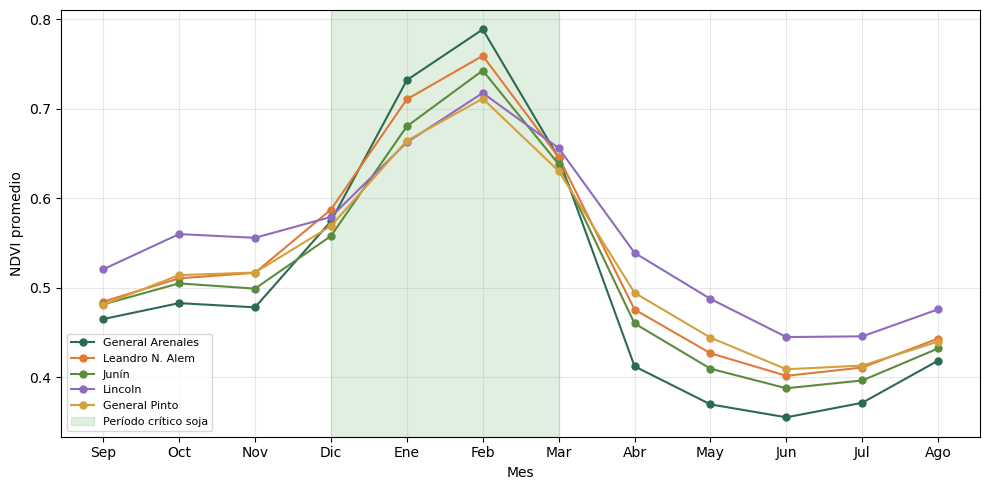

In [3]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

# Paleta fija por partido (consistente en todas las figuras)
COLOR_PARTIDOS = {
    "General Arenales": "#2D6A4F",
    "Leandro N. Alem":  "#E07A3A",
    "Junín":            "#5B8C3E",
    "Lincoln":          "#8E6BBF",
    "General Pinto":    "#D4A03C",
}
PARTIDOS = list(COLOR_PARTIDOS.keys())

df_ndvi = pd.read_csv(DATA_RAW / "ndvi" / "ndvi_modis_zona_coop_2000_2025.csv", parse_dates=["fecha"])


df_ndvi["mes"] = df_ndvi["fecha"].dt.month
orden_meses = [9,10,11,12,1,2,3,4,5,6,7,8]
meses_label = ["Sep","Oct","Nov","Dic","Ene","Feb","Mar","Abr","May","Jun","Jul","Ago"]

fig, ax = plt.subplots(figsize=(10, 5))
for partido in PARTIDOS:
    dp = df_ndvi[df_ndvi["partido"] == partido]
    ciclo = dp.groupby("mes")["ndvi"].mean().reindex(orden_meses)
    ax.plot(range(12), ciclo.values, marker="o", markersize=5, linewidth=1.5,
            label=partido, color=COLOR_PARTIDOS[partido])

ax.axvspan(3, 6, alpha=0.12, color="green", label="Período crítico soja")
ax.set_xticks(range(12))
ax.set_xticklabels(meses_label)
ax.set_ylabel("NDVI promedio")
ax.set_xlabel("Mes")
ax.legend(loc="lower left", fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUTS / "figura1_ciclo_ndvi.png", dpi=200, bbox_inches="tight")
plt.show()


# Figura2

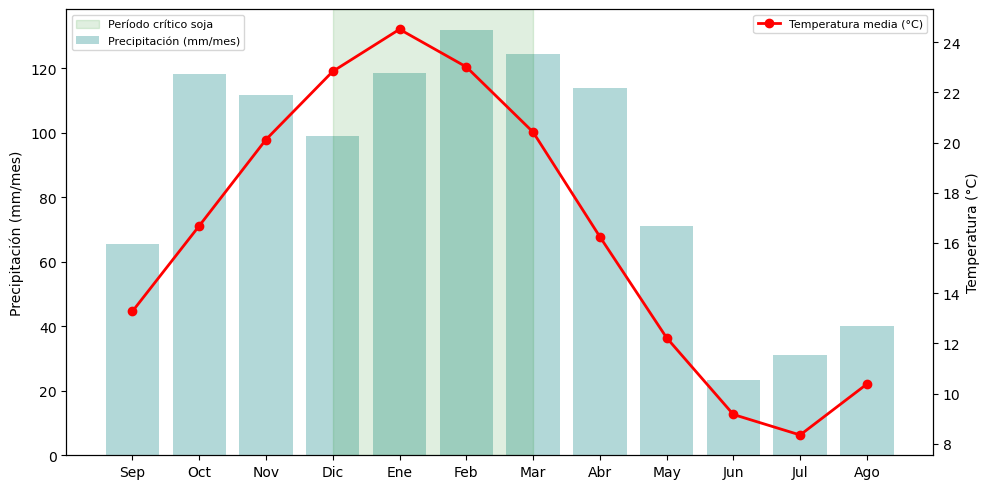

In [4]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

df_clima = pd.read_csv(DATA_RAW / "nasa_power" / "nasa_power_zona_coop_1999_2025.csv", parse_dates=["fecha"])

clima_mensual = df_clima.groupby(df_clima["fecha"].dt.month).agg({"T2M": "mean", "PRECTOTCORR": "mean"})
orden = [9,10,11,12,1,2,3,4,5,6,7,8]
meses = ["Sep","Oct","Nov","Dic","Ene","Feb","Mar","Abr","May","Jun","Jul","Ago"]
clima_ordenado = clima_mensual.reindex(orden)

fig, ax = plt.subplots(figsize=(10, 5))
ax2 = ax.twinx()
ax.bar(range(12), clima_ordenado["PRECTOTCORR"] * 30, alpha=0.3, color="teal", label="Precipitación (mm/mes)")
ax2.plot(range(12), clima_ordenado["T2M"], color="red", linewidth=2, marker="o", label="Temperatura media (°C)")
ax.axvspan(3, 6, alpha=0.12, color="green", label="Período crítico soja")
ax.set_xticks(range(12))
ax.set_xticklabels(meses)
ax.set_ylabel("Precipitación (mm/mes)")
ax2.set_ylabel("Temperatura (°C)")
ax.legend(loc="upper left", fontsize=8)
ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUTS / "figura2_climatologia.png", dpi=200, bbox_inches="tight")
plt.show()

# Figura3

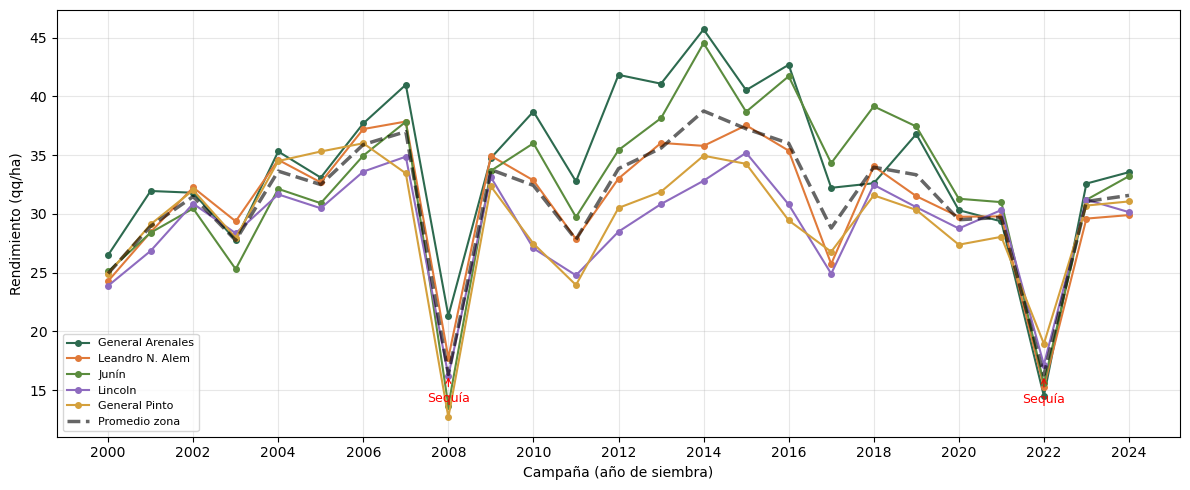

In [5]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

# Paleta fija por partido (consistente en todas las figuras)
COLOR_PARTIDOS = {
    "General Arenales": "#2D6A4F",
    "Leandro N. Alem":  "#E07A3A",
    "Junín":            "#5B8C3E",
    "Lincoln":          "#8E6BBF",
    "General Pinto":    "#D4A03C",
}
PARTIDOS = list(COLOR_PARTIDOS.keys())

df_rinde = pd.read_csv(DATA_RAW / "magyp" / "soja-serie-1941-2024.csv")

zona = df_rinde[(df_rinde["provincia"] == "Buenos Aires") & (df_rinde["departamento"].isin(PARTIDOS)) & (df_rinde["anio"] >= 2000)].copy()
zona["rinde_qq_ha"] = zona["rendimiento_kgxha"] / 100

fig, ax = plt.subplots(figsize=(12, 5))
for partido in PARTIDOS:
    datos = zona[zona["departamento"] == partido].sort_values("anio")
    ax.plot(datos["anio"], datos["rinde_qq_ha"], marker="o", markersize=4, linewidth=1.5,
            label=partido, color=COLOR_PARTIDOS[partido])

promedio = zona.groupby("anio")["rinde_qq_ha"].mean()
ax.plot(promedio.index, promedio.values, color="black", linewidth=2.5, linestyle="--", alpha=0.6, label="Promedio zona")

for year, label in [(2008, "Sequía"), (2022, "Sequía")]:
    if year in promedio.index:
        ax.annotate(label, xy=(year, promedio[year]), xytext=(0, -20),
                   textcoords="offset points", fontsize=9, color="red", ha="center",
                   arrowprops=dict(arrowstyle="->", color="red", lw=0.8))

ax.set_xlabel("Campaña (año de siembra)")
ax.set_ylabel("Rendimiento (qq/ha)")
ax.legend(loc="lower left", fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_xticks(range(2000, 2025, 2))
plt.tight_layout()
plt.savefig(OUTPUTS / "figura3_rinde_historico.png", dpi=200, bbox_inches="tight")
plt.show()


# Figura4

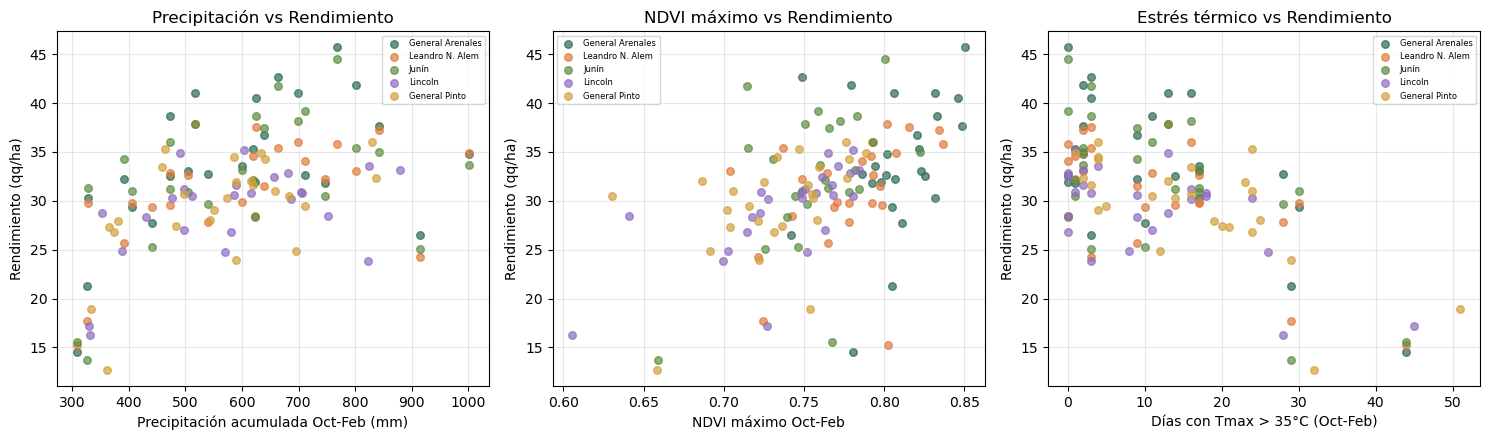

In [6]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

# Paleta fija por partido (consistente en todas las figuras)
COLOR_PARTIDOS = {
    "General Arenales": "#2D6A4F",
    "Leandro N. Alem":  "#E07A3A",
    "Junín":            "#5B8C3E",
    "Lincoln":          "#8E6BBF",
    "General Pinto":    "#D4A03C",
}
PARTIDOS = list(COLOR_PARTIDOS.keys())

df = pd.read_csv(DATA_PROCESSED / "dataset_modelado_soja.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for partido in PARTIDOS:
    dp = df[df["partido"] == partido]
    c = COLOR_PARTIDOS[partido]
    axes[0].scatter(dp["precip_acum_oct_feb"], dp["rinde_qq_ha"], s=30, alpha=0.7, label=partido, color=c)
    axes[1].scatter(dp["ndvi_max_oct_feb"], dp["rinde_qq_ha"], s=30, alpha=0.7, label=partido, color=c)
    axes[2].scatter(dp["dias_calor_extremo_oct_feb"], dp["rinde_qq_ha"], s=30, alpha=0.7, label=partido, color=c)

axes[0].set(xlabel="Precipitación acumulada Oct-Feb (mm)", ylabel="Rendimiento (qq/ha)", title="Precipitación vs Rendimiento")
axes[1].set(xlabel="NDVI máximo Oct-Feb", ylabel="Rendimiento (qq/ha)", title="NDVI máximo vs Rendimiento")
axes[2].set(xlabel="Días con Tmax > 35°C (Oct-Feb)", ylabel="Rendimiento (qq/ha)", title="Estrés térmico vs Rendimiento")

for ax in axes:
    ax.legend(fontsize=6)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUTS / "figura4_eda_features.png", dpi=200, bbox_inches="tight")
plt.show()


# Tabla1 5.2

BASELINE CLIMATOLÓGICO:
  MAE : 4.04 qq/ha
  RMSE: 6.15 qq/ha
  R²  : -0.047


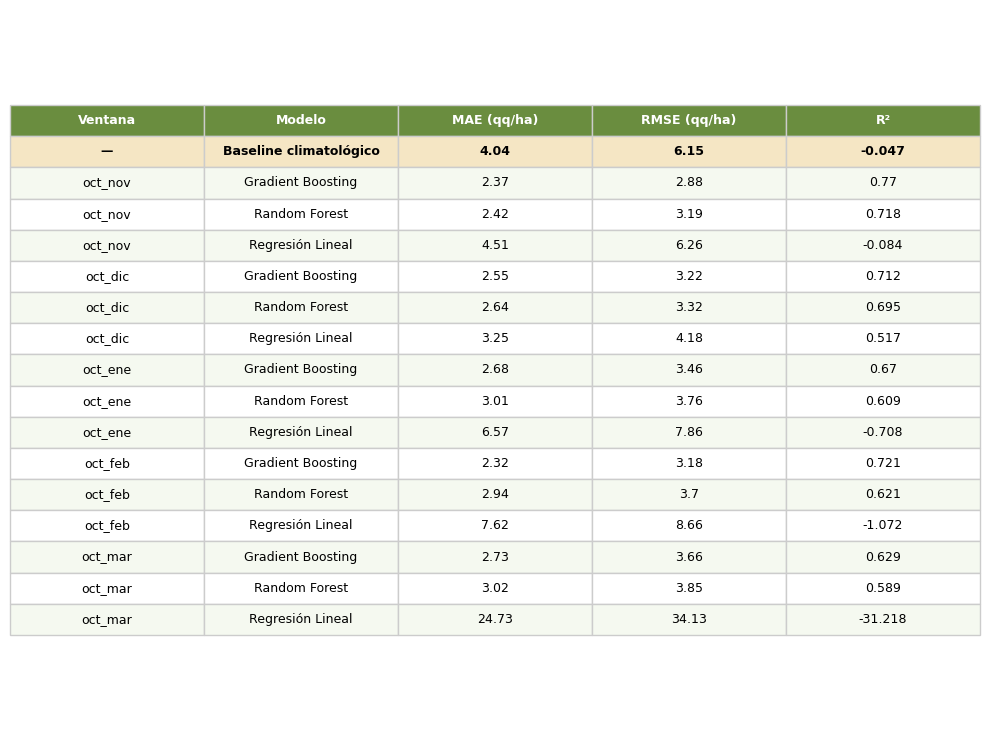


Mejora de RF oct_ene sobre baseline: 1.03 qq/ha de MAE


In [7]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(DATA_PROCESSED / "dataset_modelado_soja.csv")
results = pd.read_csv(OUTPUTS / "resultados_modelos.csv")

# Calcular baseline climatológico (promedio histórico por partido, walk-forward)
filas_base = []
for test_year in range(2016, 2025):
    train = df[df["campana"] < test_year]
    test = df[df["campana"] == test_year]
    promedios = train.groupby("partido")["rinde_qq_ha"].mean()
    for _, row in test.iterrows():
        filas_base.append({
            "real": row["rinde_qq_ha"],
            "pred": promedios[row["partido"]]
        })

base = pd.DataFrame(filas_base)
base_mae = mean_absolute_error(base["real"], base["pred"])
base_rmse = np.sqrt(mean_squared_error(base["real"], base["pred"]))
base_r2 = r2_score(base["real"], base["pred"])

print(f"BASELINE CLIMATOLÓGICO:")
print(f"  MAE : {base_mae:.2f} qq/ha")
print(f"  RMSE: {base_rmse:.2f} qq/ha")
print(f"  R²  : {base_r2:.3f}")

# Agregar baseline al dataframe de resultados (una fila por ventana no aplica, va como fila única)
baseline_row = pd.DataFrame([{
    "ventana": "—",
    "modelo": "Baseline climatológico",
    "MAE": round(base_mae, 2),
    "RMSE": round(base_rmse, 2),
    "R2": round(base_r2, 3),
}])

# Ordenar modelos
orden_ventanas = ["oct_nov", "oct_dic", "oct_ene", "oct_feb", "oct_mar"]
results["ventana"] = pd.Categorical(results["ventana"], categories=orden_ventanas, ordered=True)
results = results.sort_values(["ventana", "modelo"])

# Preparar tabla: baseline arriba, después los modelos por ventana
tabla_modelos = results[["ventana", "modelo", "MAE", "RMSE", "R2"]].copy()
tabla_modelos.columns = ["Ventana", "Modelo", "MAE (qq/ha)", "RMSE (qq/ha)", "R²"]

tabla_baseline = baseline_row[["ventana", "modelo", "MAE", "RMSE", "R2"]].copy()
tabla_baseline.columns = ["Ventana", "Modelo", "MAE (qq/ha)", "RMSE (qq/ha)", "R²"]

tabla = pd.concat([tabla_baseline, tabla_modelos], ignore_index=True)

# Generar imagen
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.axis('off')
t = ax.table(cellText=tabla.values, colLabels=tabla.columns, cellLoc='center', loc='center')
t.auto_set_font_size(False)
t.set_fontsize(9)
t.scale(1, 1.5)

for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor('#6A8D3F')
        cell.set_text_props(color='white', fontweight='bold')
    elif row == 1:  # Fila del baseline
        cell.set_facecolor('#F5E6C4')
        cell.set_text_props(fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#F5F9F0')
    cell.set_edgecolor('#CCCCCC')

plt.tight_layout()
plt.savefig(OUTPUTS / "tabla1_modelos.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

# Imprimir mejora sobre baseline para oct_ene
rf_oct_ene = results[(results["ventana"] == "oct_ene") & (results["modelo"] == "Random Forest")]
mejora = base_mae - rf_oct_ene["MAE"].values[0]
print(f"\nMejora de RF oct_ene sobre baseline: {mejora:.2f} qq/ha de MAE")

# Figura5

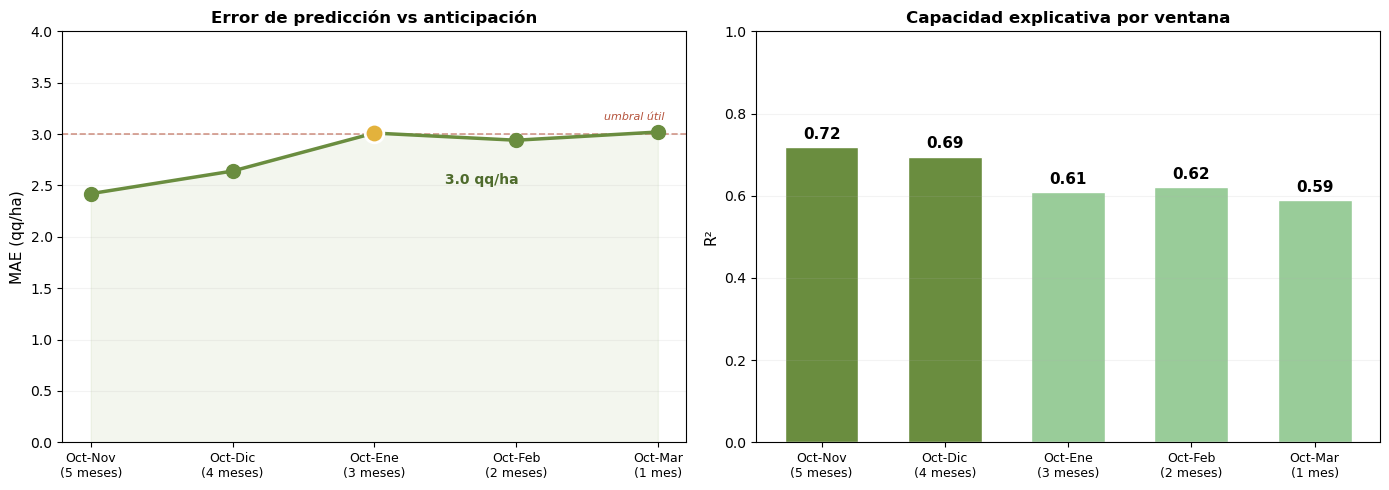

In [8]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

results = pd.read_csv(OUTPUTS / "resultados_modelos.csv")

# Filtrar solo Random Forest
rf = results[results["modelo"] == "Random Forest"].reset_index(drop=True)

labels_x = ["Oct-Nov\n(5 meses)", "Oct-Dic\n(4 meses)", "Oct-Ene\n(3 meses)", "Oct-Feb\n(2 meses)", "Oct-Mar\n(1 mes)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE por ventana
ax = axes[0]
ax.plot(range(5), rf["MAE"], marker="o", linewidth=2.5, color="#6A8D3F", markersize=10, zorder=5)
ax.fill_between(range(5), 0, rf["MAE"], alpha=0.1, color="#8BAE5D")
ax.axhline(y=3, color="#B5533C", linestyle="--", alpha=0.6, linewidth=1.2)
ax.text(4.05, 3.12, "umbral útil", fontsize=8, color="#B5533C", va="bottom", ha="right", style="italic")
ax.scatter([2], [rf.iloc[2]["MAE"]], s=180, color="#E3B23C", zorder=6, edgecolors="white", linewidths=2)
ax.annotate(f'{rf.iloc[2]["MAE"]:.1f} qq/ha', xy=(2, rf.iloc[2]["MAE"]),
           xytext=(2.5, rf.iloc[2]["MAE"]-0.5), fontsize=10, fontweight="bold", color="#4E6B2C")
ax.set_xticks(range(5))
ax.set_xticklabels(labels_x, fontsize=9)
ax.set_ylabel("MAE (qq/ha)", fontsize=11)
ax.set_title("Error de predicción vs anticipación", fontsize=12, fontweight="bold")
ax.set_ylim(0, 4)
ax.grid(True, alpha=0.15, axis="y")

# R² por ventana
ax = axes[1]
colors = ["#ff9999" if r < 0.5 else "#99cc99" if r < 0.65 else "#6A8D3F" for r in rf["R2"]]
ax.bar(range(5), rf["R2"], color=colors, edgecolor="white", width=0.6)
ax.set_xticks(range(5))
ax.set_xticklabels(labels_x, fontsize=9)
ax.set_ylabel("R²", fontsize=11)
ax.set_title("Capacidad explicativa por ventana", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.15, axis="y")
for i, r2 in enumerate(rf["R2"]):
    ax.text(i, r2 + 0.02, f"{r2:.2f}", ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUTS / "figura5_anticipacion.png", dpi=200, bbox_inches="tight")
plt.show()

# Figura6

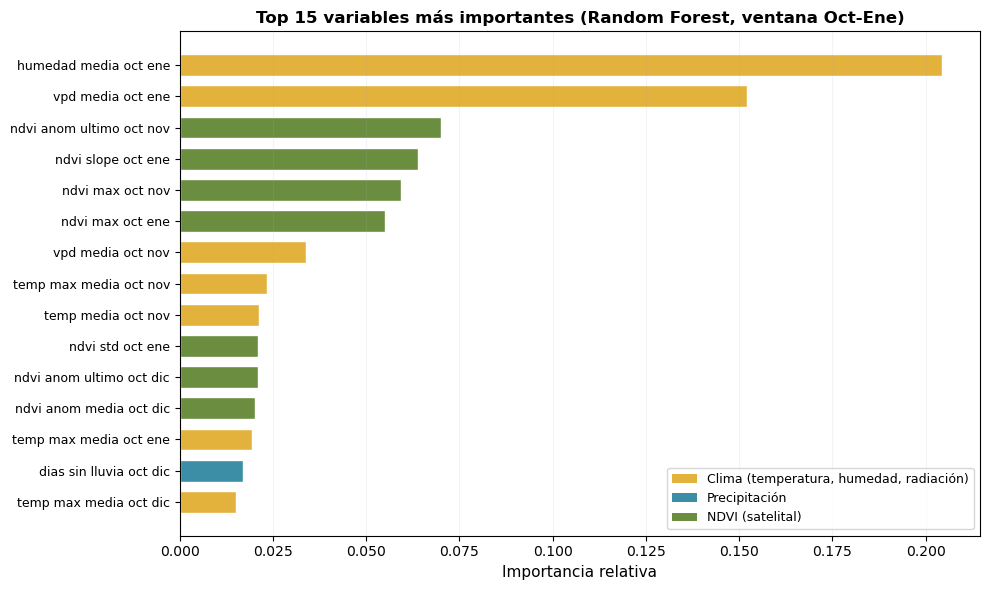

In [9]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(DATA_PROCESSED / "dataset_modelado_soja.csv")

META_COLS = ["campana", "partido", "rinde_qq_ha", "superficie_sembrada_ha", "superficie_cosechada_ha"]
VENTANAS = ["oct_nov", "oct_dic", "oct_ene"]

def get_features_ventana(ventana):
    idx = VENTANAS.index(ventana)
    vd = VENTANAS[:idx+1]
    return [c for c in df.columns if c not in META_COLS and any(c.endswith(v) for v in vd)]

features = get_features_ventana("oct_ene")
scaler = StandardScaler()
X = scaler.fit_transform(df[features])
y = df["rinde_qq_ha"].values

model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
model.fit(X, y)

# Importancia de variables
importancias = pd.Series(model.feature_importances_, index=features).sort_values(ascending=True)
top15 = importancias.tail(15)

# Colorear por tipo de variable
colores = []
for nombre in top15.index:
    if "ndvi" in nombre:
        colores.append("#6A8D3F")   # verde: satelital
    elif "precip" in nombre or "dias_sin_lluvia" in nombre:
        colores.append("#3B8EA5")   # azul: precipitación
    else:
        colores.append("#E3B23C")   # dorado: temperatura/clima

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(top15)), top15.values, color=colores, edgecolor="white", height=0.7)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels([n.replace("_", " ") for n in top15.index], fontsize=9)
ax.set_xlabel("Importancia relativa", fontsize=11)
ax.set_title("Top 15 variables más importantes (Random Forest, ventana Oct-Ene)", fontsize=12, fontweight="bold")
ax.grid(True, alpha=0.15, axis="x")

# Leyenda manual
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#E3B23C", label="Clima (temperatura, humedad, radiación)"),
    Patch(facecolor="#3B8EA5", label="Precipitación"),
    Patch(facecolor="#6A8D3F", label="NDVI (satelital)"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUTS / "figura6_importancia_variables.png", dpi=200, bbox_inches="tight")
plt.show()

# Tabla2 5.5

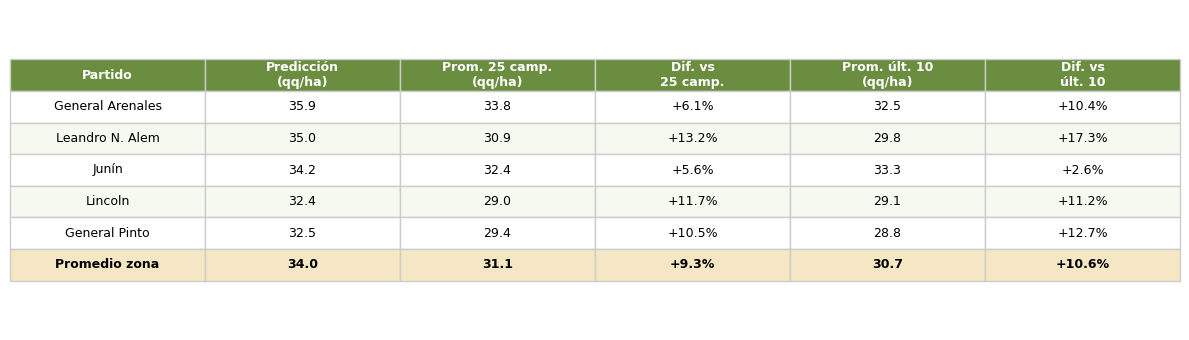


Promedio zonal últimas 10 campañas: 30.7 qq/ha
Diferencia predicción vs últimas 10: +10.6%

Detalle por partido:
  General Arenales       | Pred: 35.9 | Prom25: 33.8 (+6.1%) | Prom10: 32.5 (+10.4%)
  Leandro N. Alem        | Pred: 35.0 | Prom25: 30.9 (+13.2%) | Prom10: 29.8 (+17.3%)
  Junín                  | Pred: 34.2 | Prom25: 32.4 (+5.6%) | Prom10: 33.3 (+2.6%)
  Lincoln                | Pred: 32.4 | Prom25: 29.0 (+11.7%) | Prom10: 29.1 (+11.2%)
  General Pinto          | Pred: 32.5 | Prom25: 29.4 (+10.5%) | Prom10: 28.8 (+12.7%)
  Promedio zona          | Pred: 34.0 | Prom25: 31.1 (+9.3%) | Prom10: 30.7 (+10.6%)


In [10]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

df = pd.read_csv(DATA_PROCESSED / "dataset_modelado_soja.csv")

# Promedios por partido
hist_25 = df.groupby("partido")["rinde_qq_ha"].mean()
hist_10 = df[df["campana"] >= 2015].groupby("partido")["rinde_qq_ha"].mean()

# Predicciones 2025/26
pred_2526 = pd.read_csv(OUTPUTS / "prediccion_2526.csv").set_index("partido")["rinde_predicho"].to_dict()

# Armar tabla
filas = []
for partido in ["General Arenales", "Leandro N. Alem", "Junín", "Lincoln", "General Pinto"]:
    pred = pred_2526[partido]
    prom25 = hist_25[partido]
    prom10 = hist_10[partido]
    diff25 = ((pred - prom25) / prom25 * 100)
    diff10 = ((pred - prom10) / prom10 * 100)
    filas.append([partido, f"{pred:.1f}", f"{prom25:.1f}", f"{diff25:+.1f}%", f"{prom10:.1f}", f"{diff10:+.1f}%"])

# Fila promedio zona
pred_zona = sum(pred_2526.values()) / len(pred_2526)
prom25_zona = hist_25.mean()
prom10_zona = hist_10.mean()
diff25_zona = ((pred_zona - prom25_zona) / prom25_zona * 100)
diff10_zona = ((pred_zona - prom10_zona) / prom10_zona * 100)
filas.append(["Promedio zona", f"{pred_zona:.1f}", f"{prom25_zona:.1f}", f"{diff25_zona:+.1f}%", f"{prom10_zona:.1f}", f"{diff10_zona:+.1f}%"])

# Generar tabla como imagen
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axis('off')

columnas = ["Partido", "Predicción\n(qq/ha)", "Prom. 25 camp.\n(qq/ha)", "Dif. vs\n25 camp.", "Prom. últ. 10\n(qq/ha)", "Dif. vs\núlt. 10"]
t = ax.table(cellText=filas, colLabels=columnas, cellLoc='center', loc='center')
t.auto_set_font_size(False)
t.set_fontsize(9)
t.scale(1, 1.6)

for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor('#6A8D3F')
        cell.set_text_props(color='white', fontweight='bold')
    elif row == len(filas):
        cell.set_facecolor('#F5E6C4')
        cell.set_text_props(fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#F5F9F0')
    cell.set_edgecolor('#CCCCCC')

plt.tight_layout()
plt.savefig(OUTPUTS / "tabla2_prediccion_2526.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

# Imprimir valores para completar el texto
print(f"\nPromedio zonal últimas 10 campañas: {prom10_zona:.1f} qq/ha")
print(f"Diferencia predicción vs últimas 10: {diff10_zona:+.1f}%")
print(f"\nDetalle por partido:")
for fila in filas:
    print(f"  {fila[0]:22s} | Pred: {fila[1]} | Prom25: {fila[2]} ({fila[3]}) | Prom10: {fila[4]} ({fila[5]})")

# Figura7

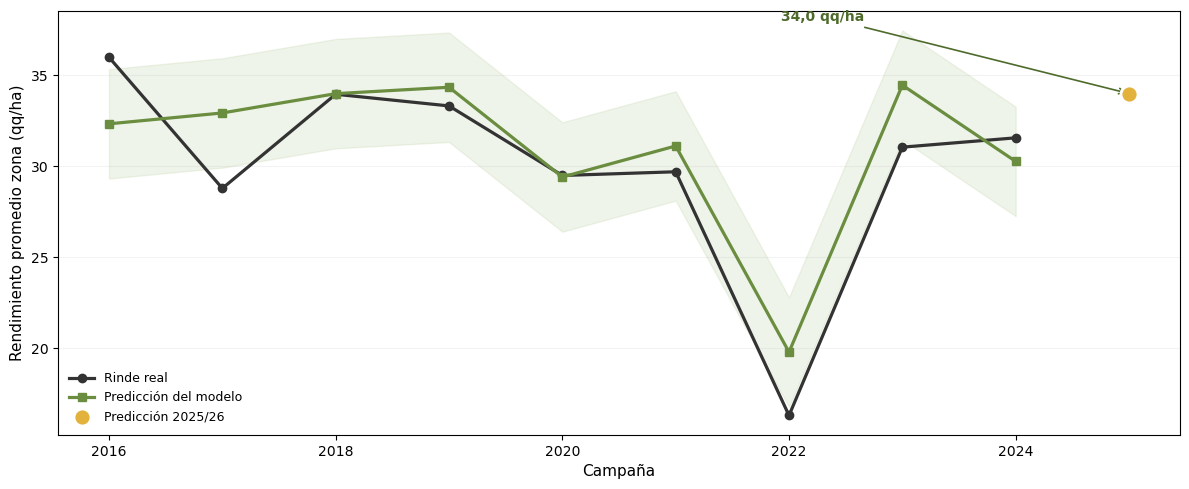

In [11]:
# Setup reutilizable: rutas del proyecto (src/config.py) y librerías.
# Está en cada celda para que cada figura pueda correrse por separado, sin depender del orden.
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

df = pd.read_csv(DATA_PROCESSED / "dataset_modelado_soja.csv")
preds = pd.read_csv(OUTPUTS / "predicciones_rf_oct_ene.csv")

# Promedio zona por campaña: real vs predicho
resumen = preds.groupby("campana").agg(
    real=("rinde_real", "mean"),
    pred=("rinde_pred", "mean")
).reset_index()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(resumen["campana"], resumen["real"], marker="o", linewidth=2.3, color="#333333", markersize=6, label="Rinde real", zorder=4)
ax.plot(resumen["campana"], resumen["pred"], marker="s", linewidth=2.3, color="#6A8D3F", markersize=6, label="Predicción del modelo", zorder=4)
res = pd.read_csv(OUTPUTS / "resultados_modelos.csv")
mae = res[(res["modelo"] == "Random Forest") & (res["ventana"] == "oct_ene")]["MAE"].iloc[0]
ax.fill_between(resumen["campana"], resumen["pred"]-mae, resumen["pred"]+mae, alpha=0.13, color="#8BAE5D")

# Predicción 2025/26
pred_zona = pd.read_csv(OUTPUTS / "prediccion_2526.csv")["rinde_predicho"].mean()
ax.scatter([2025], [pred_zona], color="#E3B23C", s=150, zorder=6, edgecolors="white", linewidths=2, label="Predicción 2025/26")
ax.annotate(f"{pred_zona:.1f} qq/ha".replace(".", ","), xy=(2025, pred_zona), xytext=(2022.3, pred_zona + 4),
           fontsize=10, fontweight="bold", color="#4E6B2C", ha="center",
           arrowprops=dict(arrowstyle="->", color="#4E6B2C", lw=1.2))

ax.set_xlabel("Campaña", fontsize=11)
ax.set_ylabel("Rendimiento promedio zona (qq/ha)", fontsize=11)
ax.legend(fontsize=9, loc="lower left", frameon=False)
ax.grid(True, alpha=0.15, axis="y")
plt.tight_layout()
plt.savefig(OUTPUTS / "figura7_prediccion_2526.png", dpi=200, bbox_inches="tight")
plt.show()

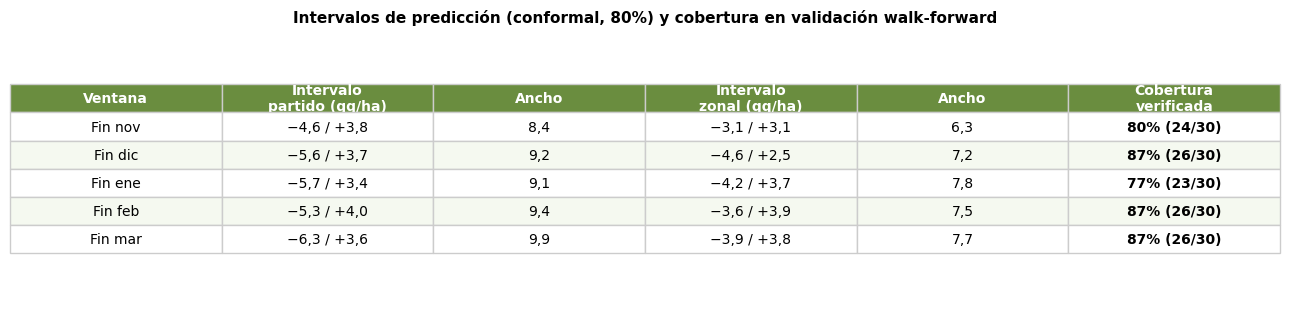

In [2]:
# Tabla 2 — Intervalos de predicción y cobertura (sección 5.5)
# Setup reutilizable
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

# --- Datos de intervalos y cobertura (del notebook 04) ---
datos = [
    ["oct_nov", "−4,6 / +3,8", "8,4", "−3,1 / +3,1", "6,3", "80% (24/30)"],
    ["oct_dic", "−5,6 / +3,7", "9,2", "−4,6 / +2,5", "7,2", "87% (26/30)"],
    ["oct_ene", "−5,7 / +3,4", "9,1", "−4,2 / +3,7", "7,8", "77% (23/30)"],
    ["oct_feb", "−5,3 / +4,0", "9,4", "−3,6 / +3,9", "7,5", "87% (26/30)"],
    ["oct_mar", "−6,3 / +3,6", "9,9", "−3,9 / +3,8", "7,7", "87% (26/30)"],
]
etiq = {"oct_nov": "Fin nov", "oct_dic": "Fin dic", "oct_ene": "Fin ene",
        "oct_feb": "Fin feb", "oct_mar": "Fin mar"}

filas = [[etiq[r[0]], r[1], r[2], r[3], r[4], r[5]] for r in datos]

columnas = ["Ventana", "Intervalo\npartido (qq/ha)", "Ancho", "Intervalo\nzonal (qq/ha)", "Ancho", "Cobertura\nverificada"]

fig, ax = plt.subplots(figsize=(13, 3.2))
ax.axis("off")
t = ax.table(cellText=filas, colLabels=columnas, cellLoc="center", loc="center")
t.auto_set_font_size(False)
t.set_fontsize(10)
t.scale(1, 1.6)

for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor("#6A8D3F")
        cell.set_text_props(color="white", fontweight="bold")
    elif row % 2 == 0:
        cell.set_facecolor("#F5F9F0")
    cell.set_edgecolor("#CCCCCC")
    # Columna de cobertura: resaltar
    if col == 5 and row > 0:
        cell.set_text_props(fontweight="bold")

ax.set_title("Intervalos de predicción (conformal, 80%) y cobertura en validación walk-forward",
             fontsize=11, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig(OUTPUTS / "tabla2_intervalos_cobertura.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

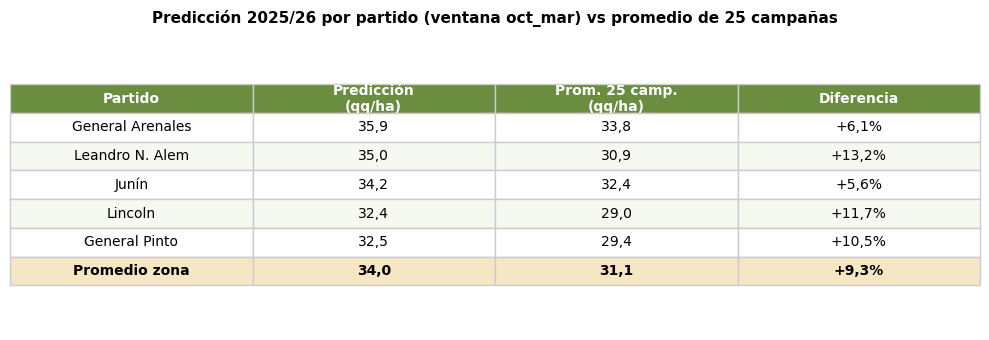

In [3]:
# Tabla 3 — Predicción 2025/26 por partido (sección 5.6)
# Setup reutilizable
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py: abrí el notebook desde la carpeta del proyecto")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import PROJECT_ROOT, DATA_RAW, DATA_PROCESSED, OUTPUTS

filas = [
    ["General Arenales", "35,9", "33,8", "+6,1%"],
    ["Leandro N. Alem",  "35,0", "30,9", "+13,2%"],
    ["Junín",            "34,2", "32,4", "+5,6%"],
    ["Lincoln",          "32,4", "29,0", "+11,7%"],
    ["General Pinto",    "32,5", "29,4", "+10,5%"],
    ["Promedio zona",    "34,0", "31,1", "+9,3%"],
]

columnas = ["Partido", "Predicción\n(qq/ha)", "Prom. 25 camp.\n(qq/ha)", "Diferencia"]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.axis("off")
t = ax.table(cellText=filas, colLabels=columnas, cellLoc="center", loc="center")
t.auto_set_font_size(False)
t.set_fontsize(10)
t.scale(1, 1.6)

for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor("#6A8D3F")
        cell.set_text_props(color="white", fontweight="bold")
    elif row == len(filas):  # Fila "Promedio zona"
        cell.set_facecolor("#F5E6C4")
        cell.set_text_props(fontweight="bold")
    elif row % 2 == 0:
        cell.set_facecolor("#F5F9F0")
    cell.set_edgecolor("#CCCCCC")

ax.set_title("Predicción 2025/26 por partido (ventana oct_mar) vs promedio de 25 campañas",
             fontsize=11, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig(OUTPUTS / "tabla3_prediccion_2526_partidos.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

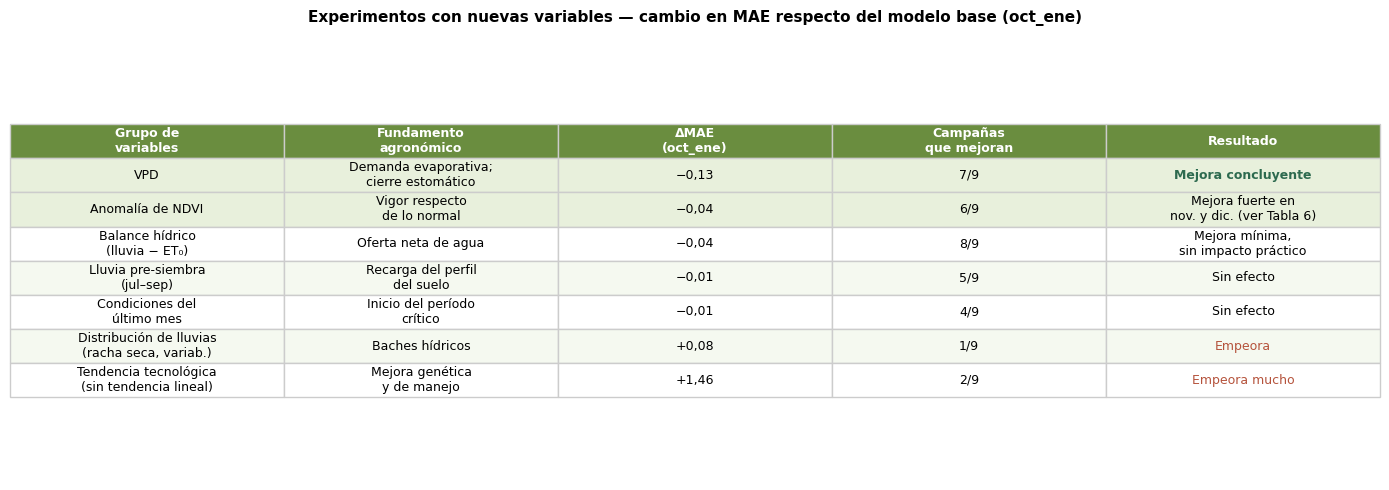

In [4]:
# Tabla 5 — Experimentos con nuevas variables (sección 5.3)
import sys
from pathlib import Path
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import OUTPUTS

filas = [
    ["VPD",                        "Demanda evaporativa;\ncierre estomático",       "−0,13",  "7/9", "Mejora concluyente"],
    ["Anomalía de NDVI",           "Vigor respecto\nde lo normal",                  "−0,04",  "6/9", "Mejora fuerte en\nnov. y dic. (ver Tabla 6)"],
    ["Balance hídrico\n(lluvia − ET₀)", "Oferta neta de agua",                      "−0,04",  "8/9", "Mejora mínima,\nsin impacto práctico"],
    ["Lluvia pre-siembra\n(jul–sep)",   "Recarga del perfil\ndel suelo",            "−0,01",  "5/9", "Sin efecto"],
    ["Condiciones del\núltimo mes",     "Inicio del período\ncrítico",              "−0,01",  "4/9", "Sin efecto"],
    ["Distribución de lluvias\n(racha seca, variab.)", "Baches hídricos",           "+0,08",  "1/9", "Empeora"],
    ["Tendencia tecnológica\n(sin tendencia lineal)",  "Mejora genética\ny de manejo", "+1,46", "2/9", "Empeora mucho"],
]

columnas = ["Grupo de\nvariables", "Fundamento\nagronómico", "ΔMAE\n(oct_ene)", "Campañas\nque mejoran", "Resultado"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.axis("off")
t = ax.table(cellText=filas, colLabels=columnas, cellLoc="center", loc="center")
t.auto_set_font_size(False)
t.set_fontsize(9)
t.scale(1, 1.8)

for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor("#6A8D3F")
        cell.set_text_props(color="white", fontweight="bold")
    elif row <= 2:  # VPD y anomalía: las que se incorporaron
        cell.set_facecolor("#E8F0DC")
    elif row % 2 == 0:
        cell.set_facecolor("#F5F9F0")
    cell.set_edgecolor("#CCCCCC")
    # Resultado negativo en rojo
    if col == 4 and row > 0 and "Empeora" in str(filas[row - 1][4]):
        cell.set_text_props(color="#B5533C")
    if col == 4 and row > 0 and "concluyente" in str(filas[row - 1][4]):
        cell.set_text_props(fontweight="bold", color="#2D6A4F")

ax.set_title("Experimentos con nuevas variables — cambio en MAE respecto del modelo base (oct_ene)",
             fontsize=11, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig(OUTPUTS / "tabla5_experimentos_variables.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

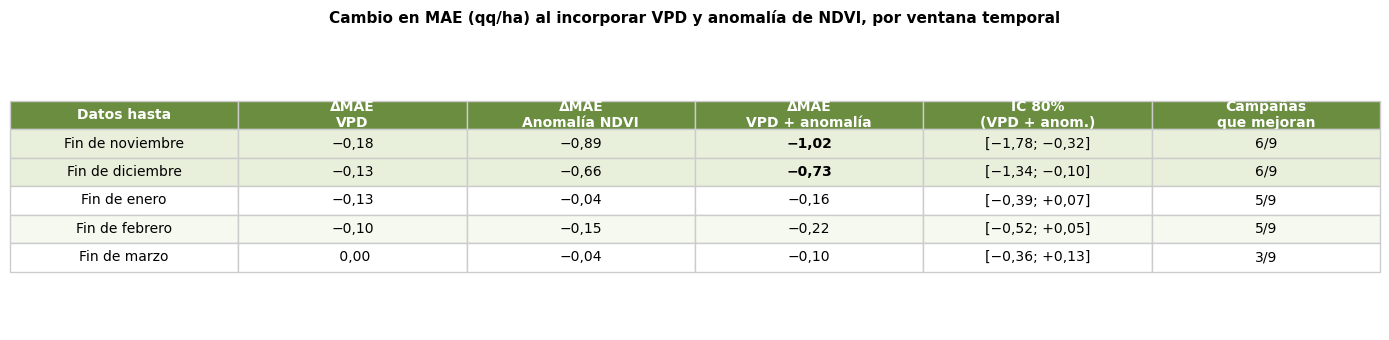

In [5]:
# Tabla 6 — Detalle VPD + anomalía por ventana (sección 5.3)
import sys
from pathlib import Path
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import OUTPUTS

filas = [
    ["Fin de noviembre", "−0,18", "−0,89", "−1,02", "[−1,78; −0,32]", "6/9"],
    ["Fin de diciembre",  "−0,13", "−0,66", "−0,73", "[−1,34; −0,10]", "6/9"],
    ["Fin de enero",      "−0,13", "−0,04", "−0,16", "[−0,39; +0,07]", "5/9"],
    ["Fin de febrero",    "−0,10", "−0,15", "−0,22", "[−0,52; +0,05]", "5/9"],
    ["Fin de marzo",      " 0,00", "−0,04", "−0,10", "[−0,36; +0,13]", "3/9"],
]

columnas = ["Datos hasta", "ΔMAE\nVPD", "ΔMAE\nAnomalía NDVI", "ΔMAE\nVPD + anomalía",
            "IC 80%\n(VPD + anom.)", "Campañas\nque mejoran"]

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.axis("off")
t = ax.table(cellText=filas, colLabels=columnas, cellLoc="center", loc="center")
t.auto_set_font_size(False)
t.set_fontsize(10)
t.scale(1, 1.6)

for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor("#6A8D3F")
        cell.set_text_props(color="white", fontweight="bold")
    elif row <= 2:  # nov y dic: donde la mejora es concluyente
        cell.set_facecolor("#E8F0DC")
        if col == 3:
            cell.set_text_props(fontweight="bold")
    elif row % 2 == 0:
        cell.set_facecolor("#F5F9F0")
    cell.set_edgecolor("#CCCCCC")

ax.set_title("Cambio en MAE (qq/ha) al incorporar VPD y anomalía de NDVI, por ventana temporal",
             fontsize=11, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig(OUTPUTS / "tabla6_vpd_anomalia_detalle.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

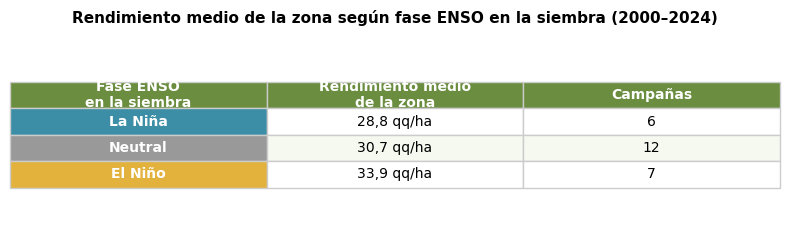

In [6]:
# Tabla 7 — ENSO y rendimiento (sección 5.4)
import sys
from pathlib import Path
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import OUTPUTS

filas = [
    ["La Niña",  "28,8 qq/ha", "6"],
    ["Neutral",  "30,7 qq/ha", "12"],
    ["El Niño",  "33,9 qq/ha", "7"],
]

columnas = ["Fase ENSO\nen la siembra", "Rendimiento medio\nde la zona", "Campañas"]

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.axis("off")
t = ax.table(cellText=filas, colLabels=columnas, cellLoc="center", loc="center")
t.auto_set_font_size(False)
t.set_fontsize(10)
t.scale(1, 1.6)

colores_enso = ["#3B8EA5", "#999999", "#E3B23C"]  # azul frío, gris neutro, dorado cálido
for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor("#6A8D3F")
        cell.set_text_props(color="white", fontweight="bold")
    elif col == 0 and row > 0:
        cell.set_facecolor(colores_enso[row - 1])
        cell.set_text_props(color="white", fontweight="bold")
    elif row % 2 == 0:
        cell.set_facecolor("#F5F9F0")
    cell.set_edgecolor("#CCCCCC")

ax.set_title("Rendimiento medio de la zona según fase ENSO en la siembra (2000–2024)",
             fontsize=11, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig(OUTPUTS / "tabla7_enso_rendimiento.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

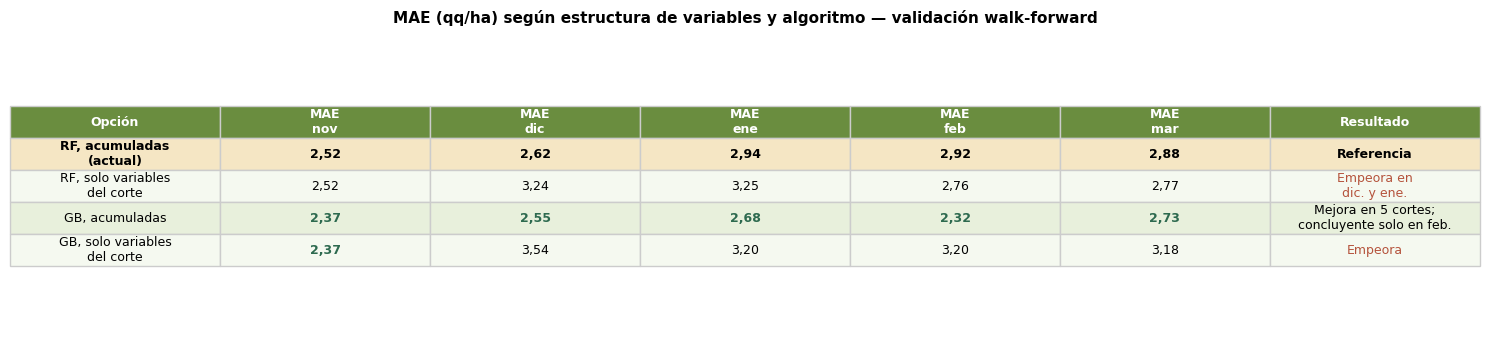

In [7]:
# Tabla 8 — RF vs GB, acumuladas vs solo corte (sección 5.5)
import sys
from pathlib import Path
import matplotlib.pyplot as plt

_raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)
if _raiz is None:
    raise FileNotFoundError("No se encontró src/config.py")
if str(_raiz / "src") not in sys.path:
    sys.path.insert(0, str(_raiz / "src"))
from config import OUTPUTS

filas = [
    ["RF, acumuladas\n(actual)",       "2,52", "2,62", "2,94", "2,92", "2,88", "Referencia"],
    ["RF, solo variables\ndel corte",  "2,52", "3,24", "3,25", "2,76", "2,77", "Empeora en\ndic. y ene."],
    ["GB, acumuladas",                 "2,37", "2,55", "2,68", "2,32", "2,73", "Mejora en 5 cortes;\nconcluyente solo en feb."],
    ["GB, solo variables\ndel corte",  "2,37", "3,54", "3,20", "3,20", "3,18", "Empeora"],
]

columnas = ["Opción", "MAE\nnov", "MAE\ndic", "MAE\nene", "MAE\nfeb", "MAE\nmar", "Resultado"]

fig, ax = plt.subplots(figsize=(15, 3.5))
ax.axis("off")
t = ax.table(cellText=filas, colLabels=columnas, cellLoc="center", loc="center")
t.auto_set_font_size(False)
t.set_fontsize(9)
t.scale(1, 1.8)

for (row, col), cell in t.get_celld().items():
    if row == 0:
        cell.set_facecolor("#6A8D3F")
        cell.set_text_props(color="white", fontweight="bold")
    elif row == 1:  # Referencia (modelo actual)
        cell.set_facecolor("#F5E6C4")
        cell.set_text_props(fontweight="bold")
    elif row == 3:  # GB acumuladas (la alternativa interesante)
        cell.set_facecolor("#E8F0DC")
    elif row % 2 == 0:
        cell.set_facecolor("#F5F9F0")
    cell.set_edgecolor("#CCCCCC")
    # Marcar en rojo las opciones que empeoran
    if col == 6 and row > 0 and "Empeora" in str(filas[row - 1][6]):
        cell.set_text_props(color="#B5533C")
    # Negrita en el mejor MAE por columna
    if col in range(1, 6) and row > 0:
        val = float(filas[row - 1][col].replace(",", "."))
        col_vals = [float(filas[r][col].replace(",", ".")) for r in range(4)]
        if val == min(col_vals):
            cell.set_text_props(fontweight="bold", color="#2D6A4F")

ax.set_title("MAE (qq/ha) según estructura de variables y algoritmo — validación walk-forward",
             fontsize=11, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig(OUTPUTS / "tabla8_rf_vs_gb.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()